# *water balance joint distribution* 

This notebook demonstrates how to compute the joint posterior distribution of water balance (wb) variables given their marginal distributions from the water balance data fusion. 

#### *outline*:
1. First, we will work through a numerical example for demonstration
2. Then, we will implement this approach to the wb data fusion output (marginal posteriors) 

In [1]:
import numpy as np
import pandas as pd
from scipy.optimize import fsolve
import matplotlib.pyplot as plt
import glob
import seaborn as sns
import os

## *demonstration*

Given the water balance equation :

$S$ = $S0$ + $P$ - $E$ - $Q$ + $C$

**Goal**: is to have a joint posterior distribution that satisfies the following:
1. the marginals
2. water balance constraint
        
For each variable, we have two sources of information:
1. **Posterior precisions (τ or tau)**: known values from data fusion
2. **Prior precisions (tau_from)**: values we need to solve for; these priors should give me back the original marginals (back calculating them) 
    

In [2]:
#let's first define the known tau:

tau = np.array([2.0,  # S
                3.0,  # S0
                1.0,  # P
                4.3,  # E
                3.2,  # Q
                1.9]) # C

variables = ['S', 'S0', 'P', 'E', 'Q', 'C']
for var, t in zip(variables, tau):
    print(f"tau{var} = {t:.1f}")


tauS = 2.0
tauS0 = 3.0
tauP = 1.0
tauE = 4.3
tauQ = 3.2
tauC = 1.9


For each variable , we establish a relationship between its posterior precision (tau) and prior precision (tau_from):

- **tau (marginals) = tau_from (prior) + tau_to (msgs from other variables)**
where **tau_to is computed as: 1/τ_to = Σ(1/τ_from_other_variables)**
- this creates a system of 6 equations that we need to solve to find the 6 prior precisions

In [3]:
def res(x,tau):
    "helper fun to compute residuals for solving the system of eqs"
    r = np.zeros(6)
    
    tau_fromS, tau_fromS0, tau_fromP, tau_fromE, tau_fromQ, tau_fromC = x
    tauS, tauS0, tauP, tauE, tauQ, tauC = tau
    
    
    #For example for S:
    #tauS (marginal) = tau_fromS (prior) + tau_toS(precision coming from messgaes from other variables)
    #or tauS - tau_fromS - tau_toS = 0 = residual (wb constraint)
    #where tau_toS can be expressed in terms of the other values:
    #tau_toS = 1/v_toS = 1/(v_fromS0 + v_fromP + v_fromE + v_fromQ + v_fromC) 
    #= 1/(1/tau_fromS0 + 1/tau_fromP + 1/tau_fromE + 1/tau_fromQ + 1/tau_fromC)
    
    r[0] = tauS - tau_fromS - 1/(1/tau_fromS0 + 1/tau_fromP + 1/tau_fromE + 1/tau_fromQ + 1/tau_fromC)
    r[1] = tauS0 - tau_fromS0 - 1/(1/tau_fromS + 1/tau_fromP + 1/tau_fromE + 1/tau_fromQ + 1/tau_fromC)
    r[2] = tauP - tau_fromP - 1/(1/tau_fromS0 + 1/tau_fromS + 1/tau_fromE + 1/tau_fromQ + 1/tau_fromC)
    r[3] = tauE - tau_fromE - 1/(1/tau_fromS0 + 1/tau_fromP + 1/tau_fromS + 1/tau_fromQ + 1/tau_fromC)
    r[4] = tauQ - tau_fromQ - 1/(1/tau_fromS0 + 1/tau_fromP + 1/tau_fromE + 1/tau_fromS + 1/tau_fromC)
    r[5] = tauC - tau_fromC - 1/(1/tau_fromS0 + 1/tau_fromP + 1/tau_fromE + 1/tau_fromQ + 1/tau_fromS)
    
    return r

In [4]:
tau_from = fsolve(lambda x: res(x, tau), tau/2) #initial guess: tau/2

In [5]:
tau_from

array([1.70913156, 2.72649963, 0.53786533, 4.03511678, 2.928378  ,
       1.60591477])

In [6]:
# check whether the res are close to zero
residuals = res(tau_from, tau)
for i, r in enumerate(residuals):
    print(f"r {i+1}: {r:.2f}")

r 1: -0.00
r 2: -0.00
r 3: -0.00
r 4: -0.00
r 5: -0.00
r 6: -0.00


- Given that S enforces the water balance relationship in the joint distribution, since: 
    $S$ = $S0$ + $P$ - $E$ - $Q$ + $C$
    
    1. a high precision from S means stronger enforcement reflecting higher correlations between variables
    2. a low precison from S means loose enforcement reflectng weaker correlations between variables

    
- for water balance coefficients written as [1, 1, -1, -1, 1] since  (S = S0 + P - E - Q + C); we use tau from S to scale this relationship (based on above reasoning)


- So, we endup with a precision matrix with two components:
    
    1.**water balance constraint**: `tau_fromS*(φ'φ)` where the matrix (φ'φ) shows how every variable is related to every other variable thru the wb eq
    2.**individual precisions**: `diag([tau_fromS0, tau_fromP, tau_fromE, tau_fromQ, tau_fromC])`

In [7]:
phi = np.array([1, 1, -1, -1, 1])  # S = S0 + P - E - Q + C
phi_term = np.outer(phi, phi) * tau_from[0]#phi'*phi term
print(np.outer(phi, phi))
diag_term = np.diag(tau_from[1:])
K = phi_term + diag_term 
print("Joint Precision Matrix K:", K)

[[ 1  1 -1 -1  1]
 [ 1  1 -1 -1  1]
 [-1 -1  1  1 -1]
 [-1 -1  1  1 -1]
 [ 1  1 -1 -1  1]]
Joint Precision Matrix K: [[ 4.43563119  1.70913156 -1.70913156 -1.70913156  1.70913156]
 [ 1.70913156  2.24699689 -1.70913156 -1.70913156  1.70913156]
 [-1.70913156 -1.70913156  5.74424834  1.70913156 -1.70913156]
 [-1.70913156 -1.70913156  1.70913156  4.63750956 -1.70913156]
 [ 1.70913156  1.70913156 -1.70913156 -1.70913156  3.31504633]]


- compute the covariance matrix

In [8]:
V = np.linalg.inv(K)
print("covariance matrix V:", V)
print("")
print("verification:")
print(f"tauS: {1/(phi @ V @ phi.T):.1f} vs. given:{tau[0]}") # var on S obtained from other vars and covars contained in V, multiply bt 2 phis to get the scalar var
print(f"tauS0: {1/V[0,0]:.1f} vs. given:{tau[1]}")
print(f"tauP: {1/V[1,1]:.1f} vs. given:{tau[2]}")
print(f"tauE: {1/V[2,2]:.1f} vs. given:{tau[3]}")
print(f"tauQ: {1/V[3,3]:.1f} vs. given: {tau[4]}")
print(f"tauC: {1/V[4,4]:.1f} vs. given:{tau[5]}")

covariance matrix V: [[ 0.33333333 -0.16949742  0.02259335  0.03113218 -0.05676938]
 [-0.16949742  1.          0.1145282   0.1578125  -0.28777036]
 [ 0.02259335  0.1145282   0.23255814 -0.02103579  0.03835867]
 [ 0.03113218  0.1578125  -0.02103579  0.3125      0.05285578]
 [-0.05676938 -0.28777036  0.03835867  0.05285578  0.52631579]]

verification:
tauS: 2.0 vs. given:2.0
tauS0: 3.0 vs. given:3.0
tauP: 1.0 vs. given:1.0
tauE: 4.3 vs. given:4.3
tauQ: 3.2 vs. given: 3.2
tauC: 1.9 vs. given:1.9


## *implementation*

In [9]:
# read posteriors (data fusion outputs)
data_path = os.path.abspath('../data')
posteriors_files = [(file, open(file, 'r').read()) 
                    for file in glob.glob(os.path.join(data_path, '*.out')) 
                    if os.path.basename(file) != 'resultsPar.out']

posteriors = {}
for file, data in posteriors_files:
    filename = os.path.splitext(os.path.basename(file))[0]
    parts = filename.split('results', 1)
    key_suffix = parts[1] if len(parts) > 1 else filename
    
    # parse the data
    parsed_data = [tuple(map(float, entry.strip('Gaussian()').replace('(', '').replace(')', '').split(','))) 
                  for entry in data.split('\n') if entry and 'Gaussian' in entry]
    
    if parsed_data:
        posteriors['mPost' + key_suffix] = [entry[0] for entry in parsed_data]
        posteriors['vPost' + key_suffix] = [entry[1] for entry in parsed_data]

# create df to hold posteriors
dfPosteriors = pd.DataFrame(posteriors)
print(dfPosteriors.head())

   mPostE  vPostE  mPostS  vPostS  mPostQ  vPostQ  mPostP   vPostP   mPostI  \
0   38.22   38.78   399.4   629.0   7.925  0.6269  55.090  98.9100  12.7100   
1   66.54   74.73   370.5   573.4   9.476  0.9003  32.790   8.9810  14.3200   
2   91.88   81.14   284.6   555.5   8.478  0.7221  13.990   4.9120   0.4244   
3  102.00  146.60   198.0   579.7   4.968  0.2472   3.813   0.5258  16.5400   
4   91.27  289.10   135.6   678.1   8.901  0.7918  21.850  37.2100  15.9900   

     vPostI  
0   9.99400  
1  12.09000  
2   0.01128  
3  15.85000  
4  15.39000  


In [10]:
mPostS0=377.8
vPostS0=762.8

- sampling from the marginal distribution

- At t=0, we use S0; for t>0, we use S0= S[t-1]

In [11]:
def resid(x, tau):
    r = np.zeros(6)  
    
    tau_fromS, tau_fromS_prev, tau_fromP, tau_fromE, tau_fromQ, tau_fromI = x
    tauS, tauS_prev, tauP, tauE, tauQ, tauI = tau
    
    r[0] = tauS - tau_fromS - 1/(1/tau_fromS_prev + 1/tau_fromP + 1/tau_fromE + 1/tau_fromQ + 1/tau_fromI)
    r[1] = tauS_prev - tau_fromS_prev - 1/(1/tau_fromS + 1/tau_fromP + 1/tau_fromE + 1/tau_fromQ + 1/tau_fromI)
    r[2] = tauP - tau_fromP - 1/(1/tau_fromS_prev + 1/tau_fromS + 1/tau_fromE + 1/tau_fromQ + 1/tau_fromI)
    r[3] = tauE - tau_fromE - 1/(1/tau_fromS_prev + 1/tau_fromP + 1/tau_fromS + 1/tau_fromQ + 1/tau_fromI)
    r[4] = tauQ - tau_fromQ - 1/(1/tau_fromS_prev + 1/tau_fromP + 1/tau_fromE + 1/tau_fromS + 1/tau_fromI)
    r[5] = tauI - tau_fromI - 1/(1/tau_fromS_prev + 1/tau_fromP + 1/tau_fromE + 1/tau_fromQ + 1/tau_fromS)
    
    return r

In [12]:
def process_t(dfPosteriors, t):
    
    if t == 0:
        # for t=0, use S0
        tau = np.array([
            1/dfPosteriors['vPostS'].iloc[0],  #tauS
            1/vPostS0,                         #tauS0
            1/dfPosteriors['vPostP'].iloc[0],  #tauP
            1/dfPosteriors['vPostE'].iloc[0],  #tauE
            1/dfPosteriors['vPostQ'].iloc[0],  #tauQ
            1/dfPosteriors['vPostI'].iloc[0]   #tauC
        ])
    else:
        # for t>0, use S[t-1]
        tau = np.array([
            1/dfPosteriors['vPostS'].iloc[t],    #tauS
            1/dfPosteriors['vPostS'].iloc[t-1],  #tauS_prev
            1/dfPosteriors['vPostP'].iloc[t],    #tauP
            1/dfPosteriors['vPostE'].iloc[t],    #tauE
            1/dfPosteriors['vPostQ'].iloc[t],    #tauQ
            1/dfPosteriors['vPostI'].iloc[t]     #tauC
        ])
    
    tau_from = fsolve(lambda x: resid(x, tau), tau/2)
    
    phi = np.array([1, 1, -1, -1, 1])
    K = np.outer(phi, phi) * tau_from[0] + np.diag(tau_from[1:])
    
    V = np.linalg.inv(K)
    
    return {
        'timestep': t,
        'tauFrom': tau_from,
        'K': K,
        'V': V,
        'tauGiven': tau#df results
    }

- process each t and verify results

In [13]:
# process all ts
results = []
for t in range(len(dfPosteriors)):
    result = process_t(dfPosteriors, t)
    results.append(result)
    
    phi = np.array([1, 1, -1, -1, 1])
    V = result['V']
    tauBack = 1/(phi @ V @ phi.T)
    
    print(f"\nt {t}:")
    print(f"given tau: {result['tauGiven'][0]:.6f}")#df results
    print(f"back-calc tau: {tauBack:.6f}")


t 0:
given tau: 0.001590
back-calc tau: 0.001590

t 1:
given tau: 0.001744
back-calc tau: 0.001744

t 2:
given tau: 0.001800
back-calc tau: 0.001800

t 3:
given tau: 0.001725
back-calc tau: 0.001725

t 4:
given tau: 0.001475
back-calc tau: 0.001475

t 5:
given tau: 0.001270
back-calc tau: 0.001270

t 6:
given tau: 0.001691
back-calc tau: 0.001691

t 7:
given tau: 0.002217
back-calc tau: 0.002217

t 8:
given tau: 0.002579
back-calc tau: 0.002579

t 9:
given tau: 0.002690
back-calc tau: 0.002690

t 10:
given tau: 0.002820
back-calc tau: 0.002820

t 11:
given tau: 0.002836
back-calc tau: 0.002836

t 12:
given tau: 0.002601
back-calc tau: 0.002601

t 13:
given tau: 0.002561
back-calc tau: 0.002561

t 14:
given tau: 0.002200
back-calc tau: 0.002200

t 15:
given tau: 0.001952
back-calc tau: 0.001952

t 16:
given tau: 0.001836
back-calc tau: 0.001836

t 17:
given tau: 0.001837
back-calc tau: 0.001837

t 18:
given tau: 0.001803
back-calc tau: 0.001803

t 19:
given tau: 0.002248
back-calc tau:

In [14]:
#print results
V_t0 = results[0]['V']
V_t1 = results[1]['V']
V_t4 = results[3]['V']
V_t5 = results[4]['V']
V_t20 = results[19]['V']
V_t55 = results[54]['V']
V_t70 = results[69]['V']
V_t110 = results[109]['V']
V_t80 = results[79]['V']
V_t93 = results[92]['V']

# a quick idea on how VPE varies
print()
print("V_PE t=0:", V_t0[1,2]) 
print("V_PE t=20:", V_t20[1,2])
print("V_PE t=55:", V_t55[1,2])
print("V_PE t=70:", V_t70[1,2])
print("V_PE t=110:", V_t110[1,2])
print("V_PE t=80:", V_t80[1,2])
print("V_PE t=93:", V_t93[1,2])


V_PE t=0: 0.27103250656679356
V_PE t=20: 43.955659226828914
V_PE t=55: 48.98337724590308
V_PE t=70: 0.36281672099216894
V_PE t=110: 0.014916264139411496
V_PE t=80: 28.147891618275843
V_PE t=93: 14.886717293533982


In [15]:
print(V_t0)

[[ 7.62800000e+02 -9.39686979e+01  3.66856793e+01  5.91456375e-01
  -9.43514938e+00]
 [-9.39686979e+01  9.89100000e+01  2.71032507e-01  4.36965886e-03
  -6.97065512e-02]
 [ 3.66856793e+01  2.71032507e-01  3.87800000e+01 -1.70592875e-03
   2.72136599e-02]
 [ 5.91456375e-01  4.36965886e-03 -1.70592875e-03  6.26900000e-01
   4.38745933e-04]
 [-9.43514938e+00 -6.97065512e-02  2.72136599e-02  4.38745933e-04
   9.99400000e+00]]


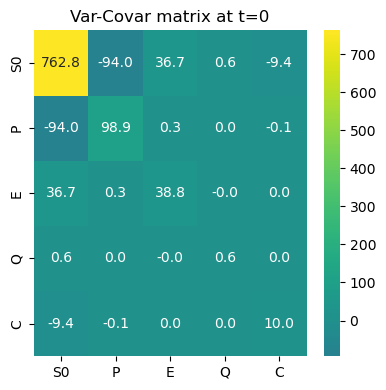

variances:
S0: 762.8
P: 98.9
E: 38.8
Q: 0.6
C: 10.0


In [16]:
varbs = ['S0', 'P', 'E', 'Q', 'C']
plt.figure(figsize=(4, 4))
sns.heatmap(V_t0, 
            xticklabels=varbs,
            yticklabels=varbs,
            annot=True,  
            fmt='.1f',   
            cmap='viridis',  
            center=0) 

plt.title('Var-Covar matrix at t=0')
plt.tight_layout()
plt.show()

print("variances:")
for i, var in enumerate(varbs):
    print(f"{var}: {V_t0[i,i]:.1f}")

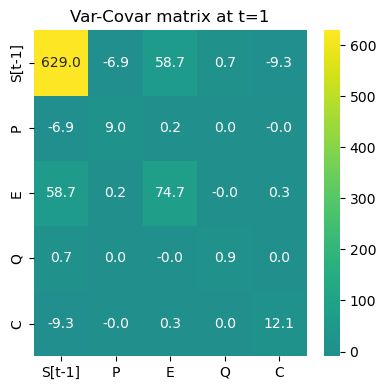

variances:
S[t-1]: 629.0
P: 9.0
E: 74.7
Q: 0.9
C: 12.1


In [17]:
varbs = ['S[t-1]', 'P', 'E', 'Q', 'C']
plt.figure(figsize=(4, 4))
sns.heatmap(V_t1, 
            xticklabels=varbs,
            yticklabels=varbs,
            annot=True,  
            fmt='.1f',   
            cmap='viridis',  
            center=0) 

plt.title('Var-Covar matrix at t=1')
plt.tight_layout()
plt.show()

print("variances:")
for i, var in enumerate(varbs):
    print(f"{var}: {V_t1[i,i]:.1f}")

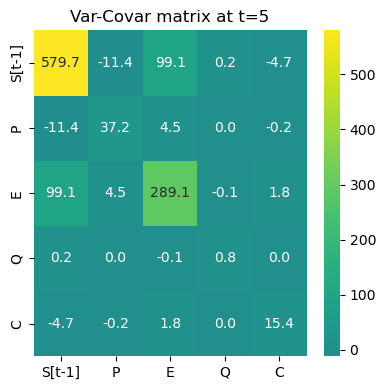

variances:
S[t-1]: 579.7
P: 37.2
E: 289.1
Q: 0.8
C: 15.4


In [18]:
varbs = ['S[t-1]', 'P', 'E', 'Q', 'C']
plt.figure(figsize=(4, 4))
sns.heatmap(V_t5, 
            xticklabels=varbs,
            yticklabels=varbs,
            annot=True,  
            fmt='.1f',   
            cmap='viridis',  
            center=0) 

plt.title('Var-Covar matrix at t=5')
plt.tight_layout()
plt.show()

print("variances:")
for i, var in enumerate(varbs):
    print(f"{var}: {V_t5[i,i]:.1f}")

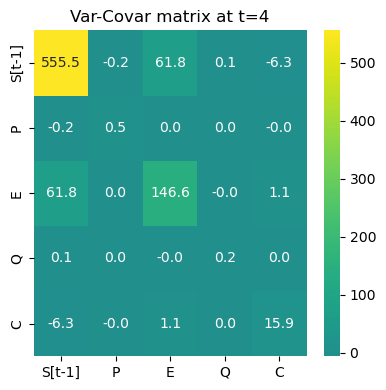

variances:
S[t-1]: 555.5
P: 0.5
E: 146.6
Q: 0.2
C: 15.9


In [19]:
varbs = ['S[t-1]', 'P', 'E', 'Q', 'C']
plt.figure(figsize=(4, 4))
sns.heatmap(V_t4, 
            xticklabels=varbs,
            yticklabels=varbs,
            annot=True,  
            fmt='.1f',   
            cmap='viridis',  
            center=0) 

plt.title('Var-Covar matrix at t=4')
plt.tight_layout()
plt.show()

print("variances:")
for i, var in enumerate(varbs):
    print(f"{var}: {V_t4[i,i]:.1f}")

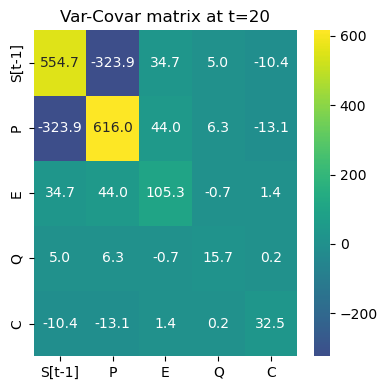

variances:
S[t-1]: 554.7
P: 616.0
E: 105.3
Q: 15.7
C: 32.5


In [20]:
varbs = ['S[t-1]', 'P', 'E', 'Q', 'C']
plt.figure(figsize=(4, 4))
sns.heatmap(V_t20, 
            xticklabels=varbs,
            yticklabels=varbs,
            annot=True,  
            fmt='.1f',   
            cmap='viridis',  
            center=0) 

plt.title('Var-Covar matrix at t=20')
plt.tight_layout()
plt.show()

print("variances:")
for i, var in enumerate(varbs):
    print(f"{var}: {V_t20[i,i]:.1f}")

In [21]:
df_vars = pd.DataFrame({
    'VarP': [r['V'][1,1] for r in results],
    'VarE': [r['V'][2,2] for r in results],
    'CovPE': [r['V'][1,2] for r in results]})

# compute var(P-E)
df_vars['VarP-E'] = df_vars['VarP'] + df_vars['VarE'] - 2*df_vars['CovPE']
df_vars.index.name = 't'

print(df_vars)
df_vars.to_csv("PosteriorCrossCorrelationPandE.csv")

          VarP        VarE     CovPE      VarP-E
t                                               
0    98.910000   38.780000  0.271033  137.147935
1     8.981000   74.730000  0.194481   83.322038
2     4.912000   81.140002  0.175896   85.700210
3     0.525800  146.600001  0.035509  147.054782
4    37.210000  289.100000  4.501945  317.306110
..         ...         ...       ...         ...
235  31.350000  560.599999  7.971754  576.006492
236  51.970000  197.300000  4.659149  239.951701
237   8.477000  277.000000  1.134651  283.207698
238   0.045610  201.800013  0.003634  201.838356
239   0.000288   90.190003  0.000003   90.190285

[240 rows x 4 columns]


In [22]:
df_vars.to_excel('df_vars.xlsx')

In [23]:
df_SE = pd.DataFrame({
    'VarS': [r['V'][0,0] for r in results],    
    'VarE': [r['V'][2,2] for r in results],    
    'CovSE': [r['V'][0,2] for r in results]    
})
df_SE['VarS-E'] = df_SE['VarS'] + df_SE['VarE'] - 2*df_SE['CovSE']

print(df_SE.head())

         VarS        VarE      CovSE      VarS-E
0  762.800000   38.780000  36.685679  728.208641
1  628.999999   74.730000  58.702379  586.325241
2  573.399962   81.140002  48.855246  556.829471
3  555.500001  146.600001  61.799064  578.501874
4  579.700003  289.100000  99.077981  670.644040


In [24]:
df_PS = pd.DataFrame({
   'VarS': [r['V'][0,0] for r in results],    
   'VarP': [r['V'][1,1] for r in results],    
   'CovPS': [r['V'][0,1] for r in results],   
})

df_PS['VarP-S'] = df_PS['VarS'] + df_PS['VarP'] - 2*df_PS['CovPS']

print(df_PS.head())

         VarS     VarP      CovPS       VarP-S
0  762.800000  98.9100 -93.968698  1049.647396
1  628.999999   8.9810  -6.920051   651.821100
2  573.399962   4.9120  -2.857853   584.027669
3  555.500001   0.5258  -0.206732   556.439264
4  579.700003  37.2100 -11.386754   639.683511


In [25]:
dates = pd.date_range(start='2003-01-01', end='2022-12-01', freq='MS')

# save outputs
for t, result in enumerate(results):
    if t < len(dates):
        #date = dates[t].strftime('%Y%m%d')
        date = dates[t].strftime('%Y.%m.%d')
        print(date)
      
        V_all = pd.DataFrame(result['V'])
        V_all.to_csv(f'../output/VjointAllvariables/V_{date}.csv', index=False, header=False)
        
        V_PE = V_all.iloc[1:3, 1:3] 
        print(V_PE)
        V_PE.to_csv(f'../output/VjointEandP/VPE_{date}.csv', index=False, header=False)

2003.01.01
           1          2
1  98.910000   0.271033
2   0.271033  38.780000
2003.02.01
          1          2
1  8.981000   0.194481
2  0.194481  74.730000
2003.03.01
          1          2
1  4.912000   0.175896
2  0.175896  81.140002
2003.04.01
          1           2
1  0.525800    0.035509
2  0.035509  146.600001
2003.05.01
           1           2
1  37.210000    4.501945
2   4.501945  289.100000
2003.06.01
           1           2
1  33.920000    1.294835
2   1.294835  138.600000
2003.07.01
            1           2
1  941.600000  108.144571
2  108.144571  230.300000
2003.08.01
            1          2
1  308.000000  14.045247
2   14.045247  88.020000
2003.09.01
           1          2
1  92.480000   3.292898
2   3.292898  59.480000
2003.10.01
          1          2
1  9.402000   0.294784
2  0.294784  48.570000
2003.11.01
          1          2
1  0.497600   0.020231
2  0.020231  59.630000
2003.12.01
          1          2
1  4.268000   0.169564
2  0.169564  54.030000
2004